In [1]:
import os
import sys
module_path = os.path.abspath(os.path.join('..'))
if module_path not in sys.path:
    sys.path.append(module_path)
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np
import polars as pl
from utils.cleaning import *
from common.helper import *
import missingno as msno

In [2]:
df = load_brfss()
dfn = load_brfss("with_null_target_v3")

In [3]:
df.describe()

,DIABETES,SEX,INCOME,ARTHRITIS,EMPHYSEMA,DEPRESSION,KIDNEY,HIGHBP,HIGHCHOL,DRINK,...,DIFFWALK,DIFFDRES,DIFFALON,HEART,STROKE,ASTHMA,SMOKER,EXERCISE,VETERAN,CANCER_DIAGNOSIS
count,1.736689e+06,1.736413e+06,1.402577e+06,1.726951e+06,1.728932e+06,1.728175e+06,1.730825e+06,1.730593e+06,1.515243e+06,1.628061e+06,...,1.668735e+06,1.669740e+06,1.663671e+06,1.720022e+06,1.732025e+06,1.723958e+06,1.651675e+06,1.678732e+06,1.728167e+06,1.728612e+06
mean,1.435887e-01,5.425783e-01,2.932089e+00,6.691574e-01,9.190807e-01,8.025449e-01,9.587931e-01,4.031485e-01,3.998448e-01,4.817737e-01,...,8.311775e-01,9.569586e-01,9.227119e-01,9.142976e-01,9.578124e-01,9.706211e-02,2.363691e+00,2.592808e-01,8.760293e-01,1.728115e-01
std,3.506723e-01,4.981839e-01,1.370426e+00,4.705166e-01,2.727112e-01,3.980787e-01,1.987686e-01,4.905303e-01,4.898664e-01,4.996678e-01,...,3.745952e-01,2.029505e-01,2.670481e-01,2.799242e-01,2.010170e-01,2.960424e-01,9.335132e-01,4.382401e-01,3.295482e-01,3.780843e-01
min,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,...,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00
25%,0.000000e+00,0.000000e+00,2.000000e+00,0.000000e+00,1.000000e+00,1.000000e+00,1.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,...,1.000000e+00,1.000000e+00,1.000000e+00,1.000000e+00,1.000000e+00,0.000000e+00,2.000000e+00,0.000000e+00,1.000000e+00,0.000000e+00
50%,0.000000e+00,1.000000e+00,4.000000e+00,1.000000e+00,1.000000e+00,1.000000e+00,1.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,...,1.000000e+00,1.000000e+00,1.000000e+00,1.000000e+00,1.000000e+00,0.000000e+00,3.000000e+00,0.000000e+00,1.000000e+00,0.000000e+00
75%,0.000000e+00,1.000000e+00,4.000000e+00,1.000000e+00,1.000000e+00,1.000000e+00,1.000000e+00,1.000000e+00,1.000000e+00,1.000000e+00,...,1.000000e+00,1.000000e+00,1.000000e+00,1.000000e+00,1.000000e+00,0.000000e+00,3.000000e+00,1.000000e+00,1.000000e+00,0.000000e+00
max,1.000000e+00,1.000000e+00,4.000000e+00,1.000000e+00,1.000000e+00,1.000000e+00,1.000000e+00,1.000000e+00,1.000000e+00,1.000000e+00,...,1.000000e+00,1.000000e+00,1.000000e+00,1.000000e+00,1.000000e+00,1.000000e+00,3.000000e+00,1.000000e+00,1.000000e+00,1.000000e+00


In [4]:
dfn.describe()

,DIABETES,SEX,INCOME,ARTHRITIS,EMPHYSEMA,DEPRESSION,KIDNEY,HIGHBP,HIGHCHOL,DRINK,...,DIFFWALK,DIFFDRES,DIFFALON,HEART,STROKE,ASTHMA,SMOKER,EXERCISE,VETERAN,CANCER_DIAGNOSIS
count,1.736689e+06,1.740016e+06,1.404398e+06,1.729505e+06,1.731553e+06,1.730789e+06,1.733409e+06,1.733498e+06,1.517348e+06,1.630917e+06,...,1.671719e+06,1.672746e+06,1.666642e+06,1.722611e+06,1.734737e+06,1.726621e+06,1.654616e+06,1.681911e+06,1.731378e+06,1.731217e+06
mean,1.435887e-01,5.424375e-01,2.931049e+00,6.690984e-01,9.189918e-01,8.024387e-01,9.587639e-01,4.032811e-01,3.999406e-01,4.820276e-01,...,8.309614e-01,9.568452e-01,9.225581e-01,9.142308e-01,9.577665e-01,9.713075e-02,2.363554e+00,2.594668e-01,8.760386e-01,1.727842e-01
std,3.506723e-01,4.981959e-01,1.370948e+00,4.705378e-01,2.728478e-01,3.981595e-01,1.988358e-01,4.905564e-01,4.898860e-01,4.996770e-01,...,3.747861e-01,2.032055e-01,2.672915e-01,2.800230e-01,2.011215e-01,2.961358e-01,9.336738e-01,4.383422e-01,3.295376e-01,3.780607e-01
min,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,...,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00
25%,0.000000e+00,0.000000e+00,2.000000e+00,0.000000e+00,1.000000e+00,1.000000e+00,1.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,...,1.000000e+00,1.000000e+00,1.000000e+00,1.000000e+00,1.000000e+00,0.000000e+00,2.000000e+00,0.000000e+00,1.000000e+00,0.000000e+00
50%,0.000000e+00,1.000000e+00,4.000000e+00,1.000000e+00,1.000000e+00,1.000000e+00,1.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,...,1.000000e+00,1.000000e+00,1.000000e+00,1.000000e+00,1.000000e+00,0.000000e+00,3.000000e+00,0.000000e+00,1.000000e+00,0.000000e+00
75%,0.000000e+00,1.000000e+00,4.000000e+00,1.000000e+00,1.000000e+00,1.000000e+00,1.000000e+00,1.000000e+00,1.000000e+00,1.000000e+00,...,1.000000e+00,1.000000e+00,1.000000e+00,1.000000e+00,1.000000e+00,0.000000e+00,3.000000e+00,1.000000e+00,1.000000e+00,0.000000e+00
max,1.000000e+00,1.000000e+00,4.000000e+00,1.000000e+00,1.000000e+00,1.000000e+00,1.000000e+00,1.000000e+00,1.000000e+00,1.000000e+00,...,1.000000e+00,1.000000e+00,1.000000e+00,1.000000e+00,1.000000e+00,1.000000e+00,3.000000e+00,1.000000e+00,1.000000e+00,1.000000e+00


In [5]:
df.DIABETES.value_counts()

DIABETES
0    1487320
1     249369
Name: count, dtype: int64

In [6]:
dfn.DIABETES.value_counts(dropna=False)

DIABETES
0.0    1487320
1.0     249369
NaN       3611
Name: count, dtype: int64

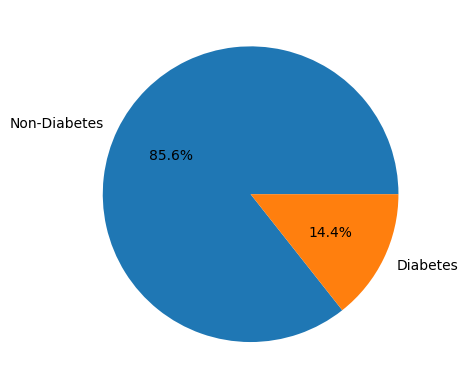

In [7]:
fig, ax = plt.subplots()
ax.pie(x=df.DIABETES.value_counts(), labels=["Non-Diabetes", "Diabetes"], autopct='%1.1f%%')
plt.show()

In [8]:
dfn.DIABETES.value_counts(dropna=False)

DIABETES
0.0    1487320
1.0     249369
NaN       3611
Name: count, dtype: int64

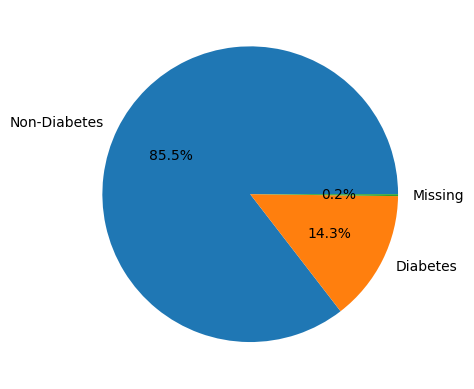

In [9]:
fig, ax = plt.subplots()
ax.pie(x=dfn.DIABETES.value_counts(dropna=False), labels=["Non-Diabetes", "Diabetes", "Missing"], autopct='%1.1f%%', radius=1)
plt.show()

In [10]:
df[["DIABETES", "SEX"]].groupby(by="DIABETES").value_counts(dropna=False)

DIABETES  SEX
0         1.0    805147
          0.0    681936
          NaN       237
1         1.0    136993
          0.0    112337
          NaN        39
Name: count, dtype: int64

In [11]:
for col in df.columns:

    if col == 'DIABETES':
        continue

    c = df[col].value_counts(dropna=False)
    p = df[col].value_counts(dropna=False, normalize=True)
    

    if col == 'DIABETES':
        r = pd.concat([c, p], axis=1, keys=['counts', '%'])
        continue

    diab_c = df[["DIABETES", col]].groupby(by="DIABETES").value_counts(dropna=False)
    diab_p = df[["DIABETES", col]].groupby(by="DIABETES").value_counts(dropna=False, normalize=True)

    r = pd.concat([c, p, diab_c[0], diab_p[0], diab_c[1], diab_p[1]], axis=1, keys=['counts', '%', 'dn_counts', 'dn_%', 'dy_counts', 'dy_%'])
    print(r)
    print()

     counts         %  dn_counts      dn_%  dy_counts      dy_%
SEX                                                            
1.0  942140  0.542492     805147  0.541341     136993  0.549359
0.0  794273  0.457349     681936  0.458500     112337  0.450485
NaN     276  0.000159        237  0.000159         39  0.000156

        counts         %  dn_counts      dn_%  dy_counts      dy_%
INCOME                                                            
4.0     757923  0.436418     677208  0.455321      80715  0.323677
NaN     334112  0.192384     286026  0.192310      48086  0.192831
3.0     195332  0.112474     165129  0.111025      30203  0.121118
1.0     182052  0.104827     144724  0.097305      37328  0.149690
2.0     156370  0.090039     128761  0.086572      27609  0.110715
0.0     110900  0.063857      85472  0.057467      25428  0.101969

            counts         %  dn_counts      dn_%  dy_counts      dy_%
ARTHRITIS                                                             


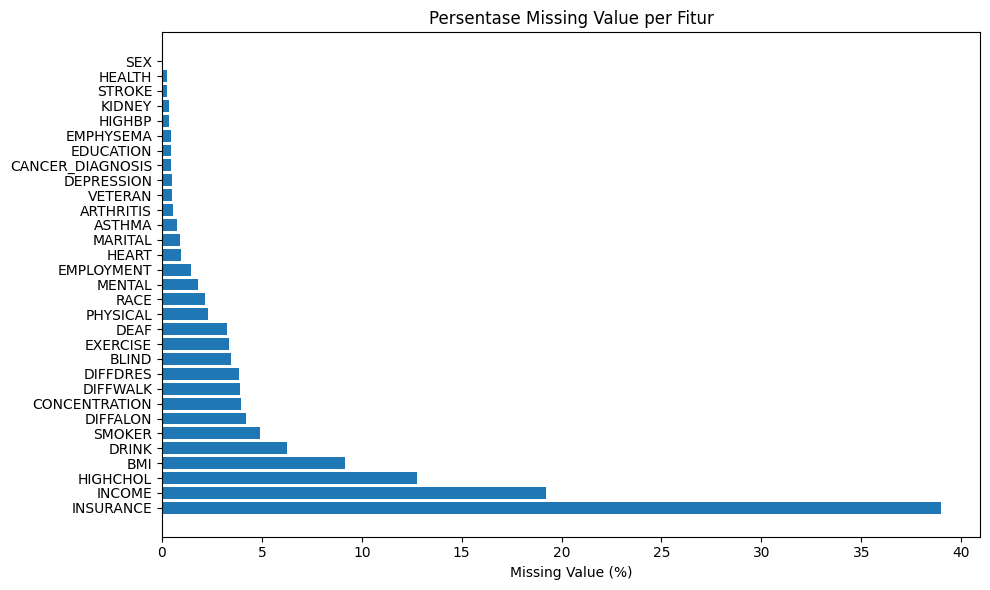

In [12]:
import matplotlib.pyplot as plt
import numpy as np

# Calculate missing percentage per feature
missing_pct = (df.isna().sum() / len(df) * 100).sort_values(ascending=False)
missing_pct = missing_pct[missing_pct > 0]  # only features with missing

fig, ax = plt.subplots(figsize=(10, 6))
ax.barh(missing_pct.index, missing_pct.values)
ax.set_xlabel('Missing Value (%)')
ax.set_title('Persentase Missing Value per Fitur')
plt.tight_layout()
plt.show()

<Axes: >

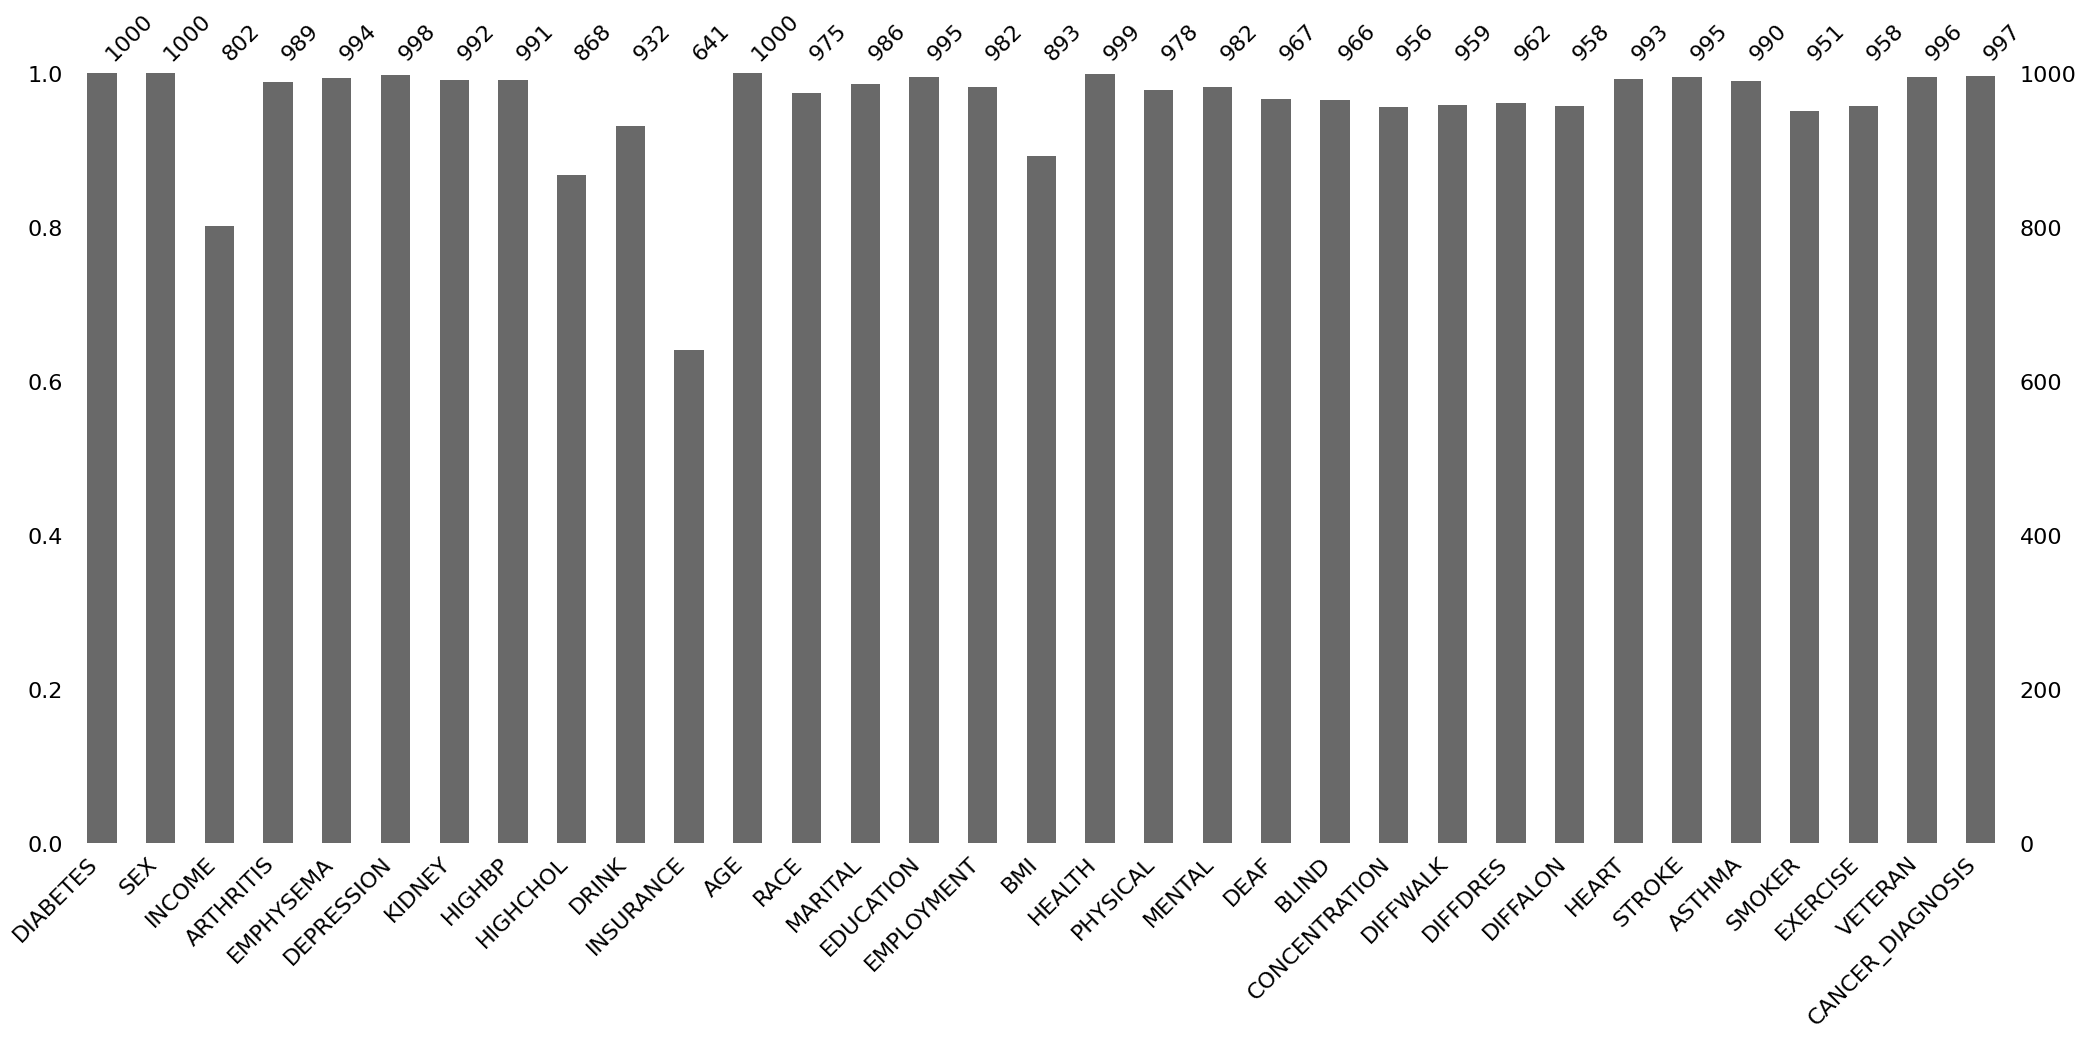

In [13]:
msno.bar(df.sample(1000))